# Instructor answer sheet: Hard Negative Mining with Fashion-MNIST

This is the completed companion to the student assignment. It includes the same runnable experiment plus suggested answers and teaching notes.

**Important:** Exact metrics depend on the hardware, PyTorch version, randomisation details and training run. Do not treat particular accuracy values as the expected answer. Assess whether students understand the selection mechanism and can interpret their own measurements.

## Teaching objective and experiment design

The binary task is **sneaker vs. not sneaker**. Fashion-MNIST class 7 (Sneaker) is positive; the other nine classes are negative.

The notebook deliberately separates:
- a small initial training set containing positives and randomly selected negatives;
- a candidate pool containing additional, known negative examples;
- the untouched test set used only for final evaluation.

The baseline trains on the initial random negatives. The hard-negative model starts from the same initial examples, scores the candidate pool, adds high-scoring negatives, and continues training. This is a simple form of **online hard negative mining**: the current model helps decide which examples should be added next.

## 0. Setup

In [1]:
# Imports and reproducibility
import random
import time
import numpy as np
import matplotlib.pyplot as plt
import torch
from torch import nn
from torch.utils.data import DataLoader, TensorDataset
from torchvision import datasets

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using:", device)
if device.type == "cuda":
    print("GPU:", torch.cuda.get_device_name(0))


Using: cpu


## 1. Load Fashion-MNIST

Fashion-MNIST contains 28×28 grayscale images from 10 clothing categories. We turn it into a **binary classification** problem:

- **Positive (label 1):** Sneaker (original Fashion-MNIST class 7)
- **Negative (label 0):** Any other clothing item

This makes hard negative mining easy to see: a hard negative is a non-sneaker image that the model gives a high sneaker score.

In [2]:
# Download happens only the first time. The dataset is small.
train_raw = datasets.FashionMNIST(root="data", train=True, download=True)
test_raw  = datasets.FashionMNIST(root="data", train=False, download=True)

# Convert images to float tensors in the range [0, 1].
X_train = train_raw.data.unsqueeze(1).float() / 255.0
y_train = (train_raw.targets == 7).long()   # 1 = sneaker, 0 = not sneaker
X_test = test_raw.data.unsqueeze(1).float() / 255.0
y_test = (test_raw.targets == 7).long()

print("Training images:", len(X_train))
print("Test images:", len(X_test))
print("Positive training examples (sneakers):", int(y_train.sum()))
print("Negative training examples (not sneakers):", int((y_train == 0).sum()))

100.0%
100.0%
100.0%
100.0%


Training images: 60000
Test images: 10000
Positive training examples (sneakers): 6000
Negative training examples (not sneakers): 54000


### Look at a few examples

The title above each image tells you its binary label. Notice that the negative class contains many visually different types of clothing.

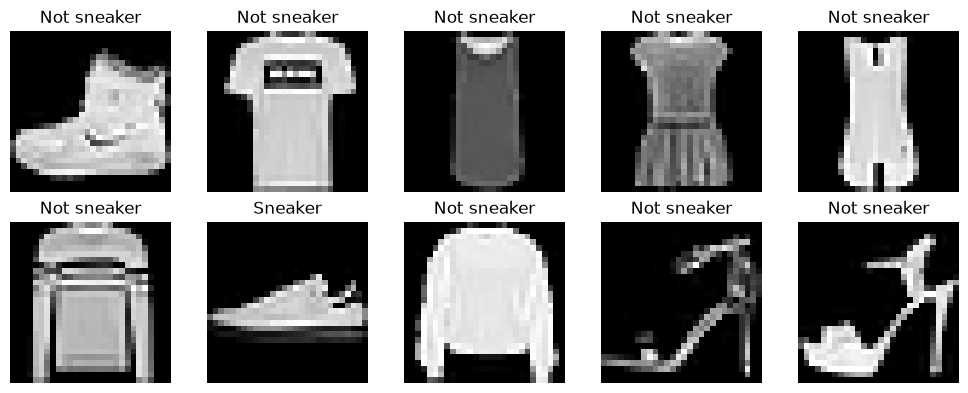

In [3]:
class_names = ["Not sneaker", "Sneaker"]
fig, axes = plt.subplots(2, 5, figsize=(10, 4))
for ax, idx in zip(axes.flat, range(10)):
    ax.imshow(X_train[idx, 0], cmap="gray")
    ax.set_title(class_names[int(y_train[idx])])
    ax.axis("off")
plt.tight_layout()
plt.show()

## 2. Create a small training set and a separate mining pool

To demonstrate mining, we deliberately do **not** start with every negative example.

- We use 2,500 sneaker images as positives.
- We start with 1,500 randomly selected negatives.
- We keep 5,000 additional negatives in a separate **candidate pool**.

The model will inspect the candidate pool and select the negatives it currently finds most confusing. The test set stays untouched until evaluation.

In [4]:
g = torch.Generator().manual_seed(SEED)
positive_ids = torch.where(y_train == 1)[0]
negative_ids = torch.where(y_train == 0)[0]
positive_ids = positive_ids[torch.randperm(len(positive_ids), generator=g)]
negative_ids = negative_ids[torch.randperm(len(negative_ids), generator=g)]

N_POSITIVE = 2500
N_INITIAL_NEGATIVE = 1500
N_CANDIDATE = 5000

pos_ids = positive_ids[:N_POSITIVE]
initial_neg_ids = negative_ids[:N_INITIAL_NEGATIVE]
candidate_ids = negative_ids[N_INITIAL_NEGATIVE:N_INITIAL_NEGATIVE + N_CANDIDATE]

X_pos, y_pos = X_train[pos_ids], y_train[pos_ids]
X_initial_neg = X_train[initial_neg_ids]
X_pool = X_train[candidate_ids]

print("Initial positives:", len(X_pos))
print("Initial negatives:", len(X_initial_neg))
print("Unseen negative candidates:", len(X_pool))

Initial positives: 2500
Initial negatives: 1500
Unseen negative candidates: 5000


## 3. Build a small convolutional neural network

A compact CNN is enough for this classroom experiment. The final layer returns **one logit**. Applying `sigmoid` converts it into a score between 0 and 1: higher means "more likely to be a sneaker".

In [5]:
class SmallCNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(1, 16, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),
            nn.Conv2d(16, 32, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),
            nn.Flatten()
        )
        self.classifier = nn.Linear(32 * 7 * 7, 1)

    def forward(self, x):
        return self.classifier(self.features(x)).squeeze(1)

def make_model():
    return SmallCNN().to(device)

def make_loader(X_pos, X_neg, batch_size=128):
    X = torch.cat([X_pos, X_neg])
    y = torch.cat([
        torch.ones(len(X_pos)),
        torch.zeros(len(X_neg))
    ])
    dataset = TensorDataset(X, y)
    return DataLoader(dataset, batch_size=batch_size, shuffle=True)

def train_model(model, loader, epochs=2):
    model.train()
    optimizer = torch.optim.Adam(model.parameters(), lr=0.001)
    loss_fn = nn.BCEWithLogitsLoss()

    for epoch in range(epochs):
        total_loss = 0.0
        for images, labels in loader:
            images = images.to(device)
            labels = labels.to(device)

            optimizer.zero_grad()
            logits = model(images)
            loss = loss_fn(logits, labels)
            loss.backward()
            optimizer.step()
            total_loss += loss.item() * len(images)

        print(f"Epoch {epoch+1}/{epochs} - loss: {total_loss / len(loader.dataset):.4f}")
    return model

## 4. Train a baseline model (random negatives)

First train on the initial random negatives only. We call this the **baseline**. We will compare it with a model trained using hard negative mining.

In [6]:
baseline = make_model()
baseline_loader = make_loader(X_pos, X_initial_neg)
start = time.time()
baseline = train_model(baseline, baseline_loader, epochs=6)
print(f"Baseline training time: {time.time() - start:.1f} seconds")

Epoch 1/6 - loss: 0.4148
Epoch 2/6 - loss: 0.1457
Epoch 3/6 - loss: 0.1347
Epoch 4/6 - loss: 0.1271
Epoch 5/6 - loss: 0.1213
Epoch 6/6 - loss: 0.1128
Baseline training time: 2.0 seconds


## 5. Hard negative mining

For every candidate negative image, the model predicts a sneaker score. A negative image with a **high sneaker score** is a hard negative: it is not a sneaker, but the model is tempted to call it one.

We select the highest-scoring candidates, add them to the training negatives, and train for another short round. We repeat this twice.

**Important:** The candidate pool contains only negative examples. We know their true labels because we constructed the pool from Fashion-MNIST labels; in a real application, labels must be available or checked.

In [7]:
def mine_hard_negatives(model, X_candidates, number_to_mine=750):
    model.eval()
    scores = []
    with torch.no_grad():
        for start_idx in range(0, len(X_candidates), 256):
            batch = X_candidates[start_idx:start_idx + 256].to(device)
            probabilities = torch.sigmoid(model(batch))
            scores.append(probabilities.cpu())

    scores = torch.cat(scores)
    k = min(number_to_mine, len(X_candidates))
    hard_ids = torch.topk(scores, k=k).indices
    return hard_ids, scores

# Start again from a fresh model, using the same initial examples.
hnm_model = make_model()
X_mined_neg = X_initial_neg.clone()
remaining_pool = X_pool.clone()

# First short training round
hnm_loader = make_loader(X_pos, X_mined_neg)
hnm_model = train_model(hnm_model, hnm_loader, epochs=2)

# Mine and train for two rounds
mined_counts = []
for round_number in range(2):
    hard_ids, candidate_scores = mine_hard_negatives(hnm_model, remaining_pool)
    hard_images = remaining_pool[hard_ids]
    mined_counts.append(len(hard_images))

    # Add selected hard negatives to the training set.
    X_mined_neg = torch.cat([X_mined_neg, hard_images])

    # Remove selected examples so they are not mined again.
    keep = torch.ones(len(remaining_pool), dtype=torch.bool)
    keep[hard_ids] = False
    remaining_pool = remaining_pool[keep]

    print(f"Round {round_number + 1}: added {len(hard_images)} hard negatives")
    hnm_loader = make_loader(X_pos, X_mined_neg)
    hnm_model = train_model(hnm_model, hnm_loader, epochs=2)

print("Total negative training examples after mining:", len(X_mined_neg))

Epoch 1/2 - loss: 0.3874
Epoch 2/2 - loss: 0.1404
Round 1: added 750 hard negatives
Epoch 1/2 - loss: 0.2753
Epoch 2/2 - loss: 0.2392
Round 2: added 750 hard negatives
Epoch 1/2 - loss: 0.1860
Epoch 2/2 - loss: 0.1617
Total negative training examples after mining: 3000


### Inspect the mined examples

These are examples selected because the current model gave them the highest sneaker scores, even though they are all non-sneakers. The score shown is the model's predicted sneaker probability.

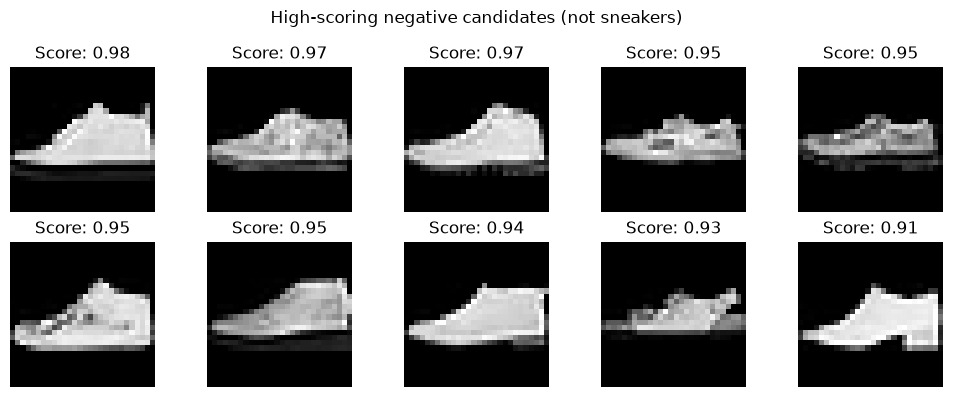

In [8]:
# Show the top-scoring examples from the original candidate pool.
hard_ids, scores = mine_hard_negatives(hnm_model, X_pool, number_to_mine=10)
fig, axes = plt.subplots(2, 5, figsize=(10, 4))
for ax, idx in zip(axes.flat, hard_ids):
    ax.imshow(X_pool[idx, 0], cmap="gray")
    ax.set_title(f"Score: {scores[idx]:.2f}")
    ax.axis("off")
plt.suptitle("High-scoring negative candidates (not sneakers)")
plt.tight_layout()
plt.show()

## 6. Evaluate on the same untouched test set

We use the same test set for both models. The threshold is 0.5:

- score ≥ 0.5 → predict sneaker
- score < 0.5 → predict not sneaker

We report **recall** (how many real sneakers are found) and **false positive rate** (how many non-sneakers are incorrectly called sneakers). Hard negative mining is particularly intended to reduce false positives.

In [9]:
def evaluate(model, X, y, threshold=0.5):
    model.eval()
    all_scores = []
    with torch.no_grad():
        for start_idx in range(0, len(X), 256):
            batch = X[start_idx:start_idx + 256].to(device)
            all_scores.append(torch.sigmoid(model(batch)).cpu())
    scores = torch.cat(all_scores)
    predictions = (scores >= threshold).long()

    positive = (y == 1)
    negative = (y == 0)
    recall = (predictions[positive] == 1).float().mean().item()
    false_positive_rate = (predictions[negative] == 1).float().mean().item()
    accuracy = (predictions == y).float().mean().item()
    return accuracy, recall, false_positive_rate

baseline_metrics = evaluate(baseline, X_test, y_test)
hnm_metrics = evaluate(hnm_model, X_test, y_test)

print("                 Accuracy   Recall   False positive rate")
print(f"Baseline         {baseline_metrics[0]:.3f}      {baseline_metrics[1]:.3f}       {baseline_metrics[2]:.3f}")
print(f"Hard negative    {hnm_metrics[0]:.3f}      {hnm_metrics[1]:.3f}       {hnm_metrics[2]:.3f}")

                 Accuracy   Recall   False positive rate
Baseline         0.897      0.996       0.114
Hard negative    0.973      0.956       0.025


## 7. Student assignment

Answer these questions in your own words. You do **not** need to write additional Python.

1. In this notebook, what makes an image a *negative* example?
2. Why do we select negative images with the highest predicted sneaker scores?
3. What is the difference between the initial random negatives and the mined hard negatives?
4. Compare the baseline and hard-negative model's **false positive rates**. Did hard negative mining reduce false positives in your run?
5. What happened to recall? Is there a trade-off between reducing false positives and finding all sneakers?
6. Why must we keep the test set separate from the mining pool?
7. Give one reason why mining only the hardest examples could be a bad idea.

**Optional experiment (change one number only):** Change `number_to_mine=750` in the mining function call to `number_to_mine=150`. Run the mining and evaluation cells again. How does selecting fewer hard negatives affect the result?

### What to submit

Submit this notebook with:
- the two evaluation results,
- your answers to questions 1–7,
- one sentence describing whether hard negative mining helped in your run.

### Key idea

Hard negative mining does not create new labels. It changes **which known negative examples the model sees during training**, prioritising examples that currently look most like positives to the model.

## Suggested answers to the student assignment

**1. What makes an image a negative example?**  
Any image that is not a sneaker. In this binary task, all nine other Fashion-MNIST categories are mapped to label 0.

**2. Why select negative images with the highest predicted sneaker scores?**  
They are the negative examples the model currently finds most confusing. The model is assigning them a high score for the positive class, so training on them directly targets false-positive behaviour.

**3. Difference between initial random negatives and mined hard negatives?**  
Initial negatives are selected without considering the model's predictions. Mined negatives are selected after scoring the candidate pool; they are the non-sneakers with the highest predicted sneaker probabilities.

**4. Compare false positive rates. Did mining reduce them?**  
Students should compare the two printed false-positive rates. A lower value for the hard-negative model means fewer non-sneakers were incorrectly classified as sneakers on the test set. The result can vary; the concept is demonstrated by the selection procedure even if one run does not improve every metric.

**5. What happened to recall? Is there a trade-off?**  
Recall measures the fraction of real sneakers detected. It may increase, decrease, or remain similar. A stricter decision boundary or a model that becomes more conservative can reduce false positives while also missing more true sneakers. Students should report the observed result rather than assume a direction.

**6. Why keep the test set separate?**  
Using test examples to choose training examples or tune the model leaks information from the evaluation data. The reported test performance would no longer be an unbiased estimate of performance on unseen data.

**7. Why might mining only the hardest examples be a bad idea?**  
Some very high-scoring negatives may be mislabeled, ambiguous, or unusual outliers. Training only on these can over-focus the model on a narrow set of cases and make training unstable. A mixture of easy, medium and hard negatives is often more robust.

**Optional experiment: mine 150 rather than 750 examples.**  
Fewer mined examples mean a smaller change to the training distribution. The effect may be weaker, but results are not guaranteed to improve monotonically: the selected examples, training dynamics and class balance all matter.

## Instructor notes: points worth emphasising

- **Hard is model-dependent.** An image is not inherently a hard negative. It is hard for a particular model at a particular stage of training.
- **The labels are still negative.** Mining changes sample selection, not the ground-truth labels.
- **This is classification-based mining.** The notebook ranks negative images by the model's positive-class probability. Object detection often mines hard background regions or proposals instead.
- **False positive rate is the key metric here.** Accuracy alone can hide the behaviour we are trying to improve.
- **No guaranteed metric improvement.** Hard negative mining is a training strategy, not a promise that every metric improves in every run.
- **Limitations of this classroom version:** the candidate pool is a fixed, labelled subset; only one binary task is considered; and the small CNN is intentionally simple.

## Optional discussion prompt

Imagine that the classifier is used in a shoe-search application. What kinds of non-sneaker images might be hard negatives? Would you expect the same hard negatives after training a larger model or collecting images from a different source? Why?

**Expected direction:** hard negatives depend on the model, data distribution and task. A boot, a low-resolution shoe image, or a visually similar item might be difficult, but the actual examples should be identified from the mined images rather than guessed in advance.